In [1]:
import re
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras import models , layers

In [2]:
text = """Deep learning is a part of machine learning. Machine learning uses data to learn patterns. Deep learning uses neural networks to learn patterns from the data. Neural networks learn from data."""
stop_words = ['is', 'of', 'a', 'an', 'the', 'from', 'to']
words = re.findall(r"[a-z]+", text.lower())
words = [w for w in words if w not in stop_words]

vocab = sorted(set(words))
word2id = {w:i for i, w in enumerate(vocab)}
id2word = {i:w for w, i in word2id.items()}

print("words:", words)
print("Vocabulary size:", len(vocab))

words: ['deep', 'learning', 'part', 'machine', 'learning', 'machine', 'learning', 'uses', 'data', 'learn', 'patterns', 'deep', 'learning', 'uses', 'neural', 'networks', 'learn', 'patterns', 'data', 'neural', 'networks', 'learn', 'data']
Vocabulary size: 10


In [8]:
x, y = [], []
for i in range(2, len(words)-2):
    context = [words[i-2], words[i-1], words[i+1], words[i+2]]
    x.append([word2id[w] for w in context])
    y.append(word2id[words[i]])

x = np.array(x)
y = np.array(y)
print("Training Examples:", len(x))
for i in range(3):
    print([id2word[j] for j in x[i]], "->", id2word[y[i]])


Training Examples: 19
['deep', 'learning', 'machine', 'learning'] -> part
['learning', 'part', 'learning', 'machine'] -> machine
['part', 'machine', 'machine', 'learning'] -> learning


In [10]:
model = models.Sequential([
    layers.Input(shape=(4,)),
    layers.Embedding(len(vocab), 50),
    layers.GlobalAveragePooling1D(),
    layers.Dense(len(vocab), activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=["accuracy"])
history = model.fit(x, y, epochs = 300, verbose=0)

print("Final Accuracy:", round(history.history["accuracy"][-1], 3))
    

Final Accuracy: 0.947


In [12]:
for i in range(5):
    pred = np.argmax(model.predict(x[i:i+1], verbose=0))
    print([id2word[j] for j in x[i]], "-> Actual:", id2word[y[i]], "| predicted:", id2word[pred])

['deep', 'learning', 'machine', 'learning'] -> Actual: part | predicted: part
['learning', 'part', 'learning', 'machine'] -> Actual: machine | predicted: machine
['part', 'machine', 'machine', 'learning'] -> Actual: learning | predicted: learning
['machine', 'learning', 'learning', 'uses'] -> Actual: machine | predicted: machine
['learning', 'machine', 'uses', 'data'] -> Actual: learning | predicted: learning


In [14]:
emb = model.layers[0].get_weights()[0]
print("vector for learning:", emb[word2id['learning']][:10], "...")
def similar(word):
    v = emb[word2id[word]]
    sims = emb @ v/ (np.linalg.norm(emb, axis=1) * np.linalg.norm(v))
    best = np.argsort(-sims)[1:6]
    return [id2word[i] for i in best]
    
print("Similar to 'learninf':", similar('learning'))
print("Similar to 'machine':", similar('machine'))

vector for learning: [ 0.24638905 -0.15050401  0.31273633 -0.36769643  0.31977734 -0.25389856
 -0.00379793  0.29776862 -0.07091328  0.0531158 ] ...
Similar to 'learninf': ['machine', 'part', 'deep', 'networks', 'learn']
Similar to 'machine': ['part', 'learning', 'deep', 'neural', 'uses']


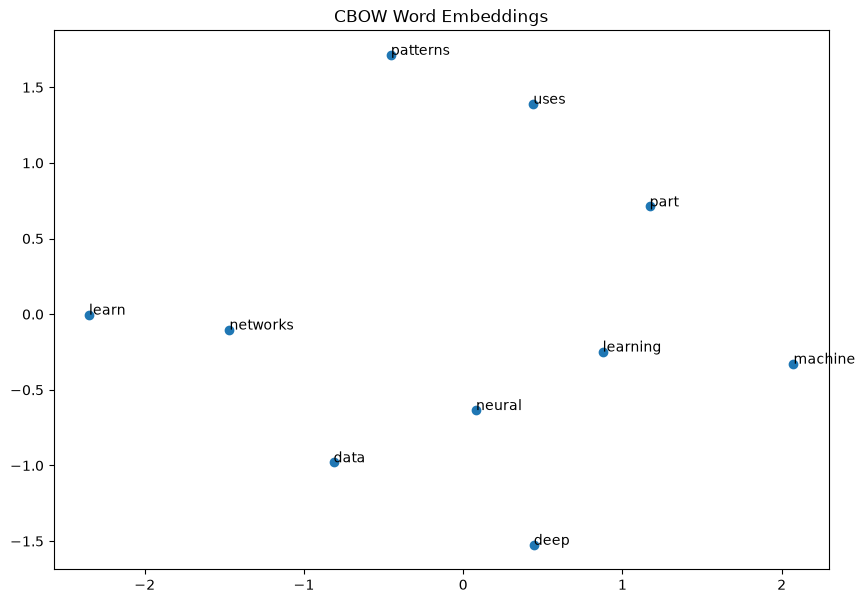

In [15]:
centered = emb - emb.mean(axis=0)
points = centered @ np.linalg.svd(centered)[2][:2].T

plt.figure(figsize=(10, 7))
plt.scatter(points[:, 0], points[:, 1])
for i, w in enumerate(vocab):
    plt.annotate(w, points[i])
plt.title("CBOW Word Embeddings")
plt.show()